# Static stickman visualizer

In [1]:
from hmp_utils.motion.body_models_constants import SmplConstants
from hmp_utils.motion.mocap_processor import MocapLoader
from hmp_utils.motion.kinematics import ForwardKinematics
from hmp_utils.visualize.static_3d_plot import plot_body_keypoints, interactive_plot_body_keypoints

### Visualize body skeleton

#### Example mocap

For convenience, an example mocap sequence from AMASS is loaded. But in general, any keypoint positional data can be visualized.

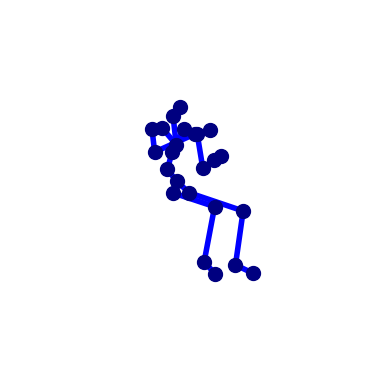

In [ ]:
filepath = "./example_mocaps/amass_sample.npz"
frame_to_plot = 0

# -- load mocap --
mocap_loader = MocapLoader(body_model_type=SmplConstants.BODY_MODEL_TYPE, keypoint_ids_to_load=SmplConstants.KEYPOINTS)
motion = mocap_loader.load_mocap(filepath)
assert motion is not None

# -- compute joint positions --
kine = ForwardKinematics(SmplConstants.OFFSETS, SmplConstants.PARENTS)
kine.set_body_model_type(SmplConstants.BODY_MODEL_TYPE)
keypoints_positions = kine.compute_fk(motion.rots, apply_root_rotation=True)
keypoints_positions = keypoints_positions[frame_to_plot]
# -- plot --
plot_body_keypoints(keypoints_positions, SmplConstants.PARENTS, azimuth=0, show_keypoint_id=False, body_rotation=(0, 0, 45))

#### AMASS Offsets

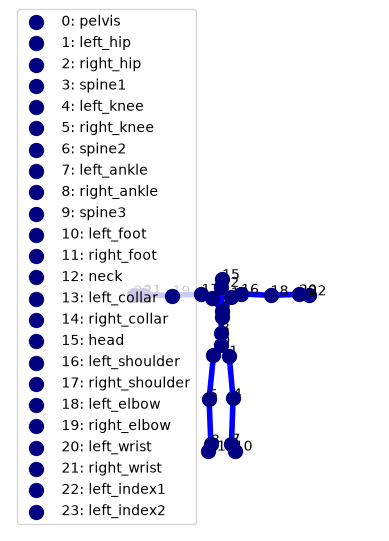

In [ ]:
plot_body_keypoints(SmplConstants.OFFSETS, SmplConstants.PARENTS, azimuth=-90, elevation=90, keypoint_names=SmplConstants.SMPLH_JOINT_NAMES, show_grid=False)

#### Plot only keypoints

If no parents are specified, the body links are not plotted, thus showing only keypoint positions.

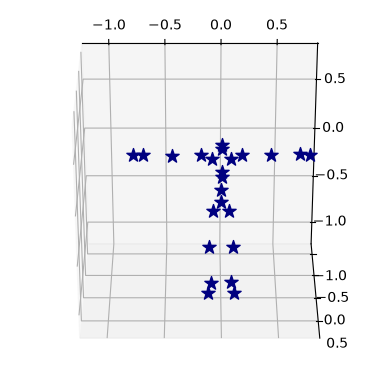

In [ ]:
plot_body_keypoints(SmplConstants.OFFSETS, azimuth=-90, elevation=120, show_grid=True, show_keypoint_id=False, keypoint_marker="*")

### Interactive

In [ ]:
interactive_plot_body_keypoints(keypoints_positions, SmplConstants.PARENTS)

interactive(children=(FloatSlider(value=20.0, description='Elevation', max=360.0), FloatSlider(value=100.0, de…

### Other examples

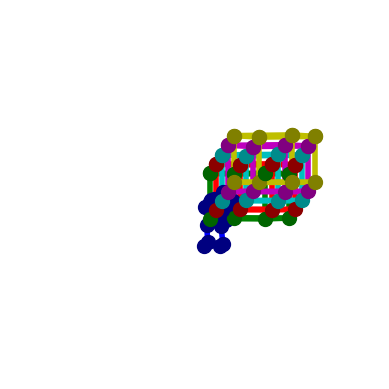

In [ ]:
import numpy as np

cube_positions = [[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1], [0, 1, 1], [0, 0, 1], [1, 0, 1], [1, 1, 1]]
cube_parents = [1, 2, 3, 0, 5, 6, 7, 4, 3, 0, 1, 2]

num_independent_bodies = 5
cube_positions = [(np.array(cube_positions) + 0.2 * i).tolist() for i in range(num_independent_bodies)]
cube_parents = [cube_parents for _ in range(num_independent_bodies)]

# keypoints_positions
# SMPL_PARENTS

plot_body_keypoints(
    [keypoints_positions, *cube_positions],
    [SmplConstants.PARENTS, *cube_parents],
    fig_opts=None,
    show_keypoint_id=False,
    keypoint_marker="o",
    azimuth=85,
    num_independent_bodies=num_independent_bodies,
    show_grid=False,
    body_rotation=(0, 0, 60),
)

In [ ]:
import numpy as np

cube_positions = [[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1], [0, 1, 1], [0, 0, 1], [1, 0, 1], [1, 1, 1]]
cube_parents = [1, 2, 3, 0, 5, 6, 7, 4, 3, 0, 1, 2]

num_cubes = 2
cube_positions = [(np.array(cube_positions) + 0.2 * i).tolist() for i in range(num_cubes)]
cube_parents = [cube_parents for _ in range(num_cubes)]

bodies = [*cube_positions, SmplConstants.OFFSETS]
parents = [*cube_parents, SmplConstants.PARENTS]

interactive_plot_body_keypoints(bodies, parents, fig_opts=None, num_independent_bodies=len(bodies))

interactive(children=(FloatSlider(value=20.0, description='Elevation', max=360.0), FloatSlider(value=100.0, de…